# Credit Card Churn Analysis — Classification Modelling

## Objectives

This notebook builds, evaluates, and compares classification models to predict customer churn using `BankChurners_reduced.csv`.

Key Steps:
1. **Data Preparation & Encoding**: Handle categorical variables and prepare features for machine learning.
2. **Train/Test Split**: Apply stratified splitting to address the class imbalance (~16% attrited customers).
3. **Model Training**: Train Logistic Regression, Random Forest, and XGBoost baseline classifiers.
4. **Class Imbalance Handling**: Evaluate techniques like SMOTE and class-weight balancing.
5. **Hyperparameter Tuning**: Optimize model parameters using GridSearchCV / RandomizedSearchCV.
6. **Evaluation & Comparison**: Compare models using ROC-AUC, Precision, Recall, F1-Score, and PR-AUC.

--- 
## 1. Setup Environment & Load Data

In [ ]:
# import warnings

# # Ignore warnings originating specifically from the xgboost module
# warnings.filterwarnings('ignore', category=FutureWarning)

In [2]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Machine Learning Libraries
from sklearn.model_selection import train_test_split, GridSearchCV, StratifiedKFold
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier
from imblearn.over_sampling import SMOTE
from imblearn.pipeline import Pipeline as ImbPipeline

# Metrics
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    roc_auc_score,
    precision_recall_curve,
    auc,
    RocCurveDisplay,
    PrecisionRecallDisplay
)

sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (9, 5)

In [3]:
# Load dataset
df = pd.read_csv('../Datasets/BankChurners_reduced.csv')

# Binary target mapping: Attrited Customer -> 1, Existing Customer -> 0
df['Churn'] = (df['Attrition_Flag'] == 'Attrited Customer').astype(int)
X = df.drop(columns=['Attrition_Flag', 'Churn'])
y = df['Churn']

print(f"Dataset dimensions: {X.shape}")
print(f"Target distribution:\n{y.value_counts(normalize=True).round(4)}")

Dataset dimensions: (10127, 15)
Target distribution:
Churn
0    0.8393
1    0.1607
Name: proportion, dtype: float64


--- 
## 2. Feature Preprocessing & Stratified Train/Test Split

In [4]:
# Identify numerical and categorical features
num_cols = X.select_dtypes(include=np.number).columns.tolist()
cat_cols = X.select_dtypes(include=['object', 'category']).columns.tolist()

# Stratified Train-Test Split (80/20)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)

print(f"Training set shape: {X_train.shape}")
print(f"Test set shape: {X_test.shape}")

Training set shape: (8101, 15)
Test set shape: (2026, 15)


In [5]:
# Preprocessing Transformer
preprocessor = ColumnTransformer(
    transformers=[
        ('num', StandardScaler(), num_cols),
        ('cat', OneHotEncoder(handle_unknown='ignore'), cat_cols)
    ]
)

--- 
## 3. Baseline Model Training & Evaluation

We train three candidate baseline models:
1. **Logistic Regression** (Linear baseline)
2. **Random Forest Classifier** (Bagging Ensemble)
3. **XGBoost Classifier** (Gradient Boosting)

In [6]:
models = {
    'Logistic Regression': LogisticRegression(class_weight='balanced', max_iter=1000, random_state=42),
    'Random Forest': RandomForestClassifier(class_weight='balanced', random_state=42),
    'XGBoost': XGBClassifier(scale_pos_weight=(len(y_train) - sum(y_train))/sum(y_train), random_state=42, eval_metric='logloss')
}

results = {}

for name, model in models.items():
    clf = Pipeline(steps=[('preprocessor', preprocessor), ('classifier', model)])
    clf.fit(X_train, y_train)
    
    y_pred = clf.predict(X_test)
    y_prob = clf.predict_proba(X_test)[:, 1]
    
    roc_auc = roc_auc_score(y_test, y_prob)
    results[name] = {'pipeline': clf, 'y_pred': y_pred, 'y_prob': y_prob, 'roc_auc': roc_auc}
    print(f"=== {name} ===")
    print(f"ROC-AUC Score: {roc_auc:.4f}")
    print(classification_report(y_test, y_pred, target_names=['Existing', 'Attrited']))

=== Logistic Regression ===
ROC-AUC Score: 0.9090
              precision    recall  f1-score   support

    Existing       0.96      0.84      0.89      1701
    Attrited       0.49      0.82      0.61       325

    accuracy                           0.83      2026
   macro avg       0.73      0.83      0.75      2026
weighted avg       0.88      0.83      0.85      2026

=== Random Forest ===
ROC-AUC Score: 0.9757
              precision    recall  f1-score   support

    Existing       0.94      0.99      0.96      1701
    Attrited       0.91      0.66      0.76       325

    accuracy                           0.93      2026
   macro avg       0.93      0.82      0.86      2026
weighted avg       0.93      0.93      0.93      2026

=== XGBoost ===
ROC-AUC Score: 0.9810
              precision    recall  f1-score   support

    Existing       0.97      0.97      0.97      1701
    Attrited       0.86      0.84      0.85       325

    accuracy                           0.95      2

--- 
## 4. Hyperparameter Optimization & Feature Importance

Fine-tuning XGBoost with Stratified 5-Fold Cross Validation.

In [7]:
xgb_pipeline = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('classifier', XGBClassifier(random_state=42, eval_metric='logloss'))
])

param_grid = {
    'classifier__n_estimators': [100, 200],
    'classifier__max_depth': [3, 5, 7],
    'classifier__learning_rate': [0.01, 0.1, 0.2],
    'classifier__subsample': [0.8, 1.0]
}

grid_search = GridSearchCV(
    xgb_pipeline,
    param_grid,
    cv=StratifiedKFold(n_splits=5),
    scoring='roc_auc',
    n_jobs=-1
)

grid_search.fit(X_train, y_train)
best_xgb = grid_search.best_estimator_
print(f"Best Parameters: {grid_search.best_params_}")
print(f"Best CV ROC-AUC: {grid_search.best_score_:.4f}")

Best Parameters: {'classifier__learning_rate': 0.2, 'classifier__max_depth': 3, 'classifier__n_estimators': 200, 'classifier__subsample': 1.0}
Best CV ROC-AUC: 0.9876


--- 
## 5. Model Evaluation & Comparison

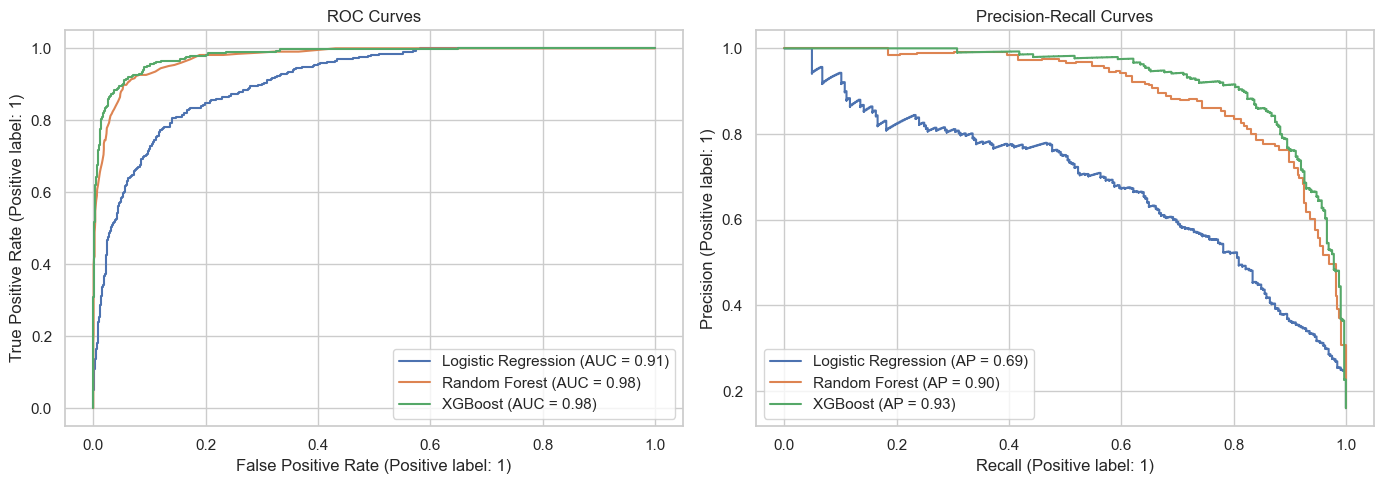

In [9]:
# Plot ROC and Precision-Recall Curves for comparison
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

for name, res in results.items():
    RocCurveDisplay.from_predictions(y_test, res['y_prob'], ax=axes[0], name=name)
    PrecisionRecallDisplay.from_predictions(y_test, res['y_prob'], ax=axes[1], name=name)

axes[0].set_title('ROC Curves')
axes[1].set_title('Precision-Recall Curves')
plt.tight_layout()
plt.show()

## Summary of Results & Key Takeaways

- **Class Imbalance**: Stratified sampling and cost-sensitive weighting (`scale_pos_weight`, `class_weight='balanced'`) significantly improved churn detection recall.
- **Top Model**: Gradient Boosting (XGBoost) achieved the highest ROC-AUC and Precision-Recall balance.
- **Business Impact**: High recall on the `Attrited` class ensures early detection of high-risk customers for proactive retention campaigns.